# Softmax Classifier

In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as ds
import matplotlib.pylab as plt
import numpy as np

In [2]:
# The function to plot parameters

def PlotParameters(model): 
    W = model.state_dict()['linear.weight'].data
    w_min = W.min().item()
    w_max = W.max().item()
    fig, axes = plt.subplots(2, 5)
    fig.subplots_adjust(hspace=0.01, wspace=0.1)
    for i, ax in enumerate(axes.flat):
        if i < 10:
            
            # Set the label for the sub-plot.
            ax.set_xlabel("class: {0}".format(i))

            # Plot the image.
            ax.imshow(W[i, :].view(28, 28), vmin=w_min, vmax=w_max, cmap='seismic')

            ax.set_xticks([])
            ax.set_yticks([])

        # Ensure the plot is shown correctly with multiple plots
        # in a single Notebook cell.
    plt.show()

In [3]:
# plot the data
def show_data(data_sample):
    plt.imshow(data_sample[0].numpy().reshape(28,28),cmap='gray')
    plt.title('y = ' + str(data_sample[1]))

## Make Some Data

In [4]:
# create and print the training dataset
train_dataset = ds.MNIST(root='./data', train=True,download=True,transform=transforms.ToTensor())
print("print the training dataset:\n", train_dataset)

100.0%
100.0%
100.0%
100.0%

print the training dataset:
 Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()


In [5]:
# create and print the validating dataset

validation_dataset = ds.MNIST(root='./data', download=True,transform=transforms.ToTensor())
print("Print the validating dataset:\n", validation_dataset)

Print the validating dataset:
 Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()


In [6]:
print("Type of data element: ",type(train_dataset[0][1]))

Type of data element:  <class 'int'>


In [7]:
# print the label
print("the label: ",train_dataset[3][1])

the label:  1


the image:  None


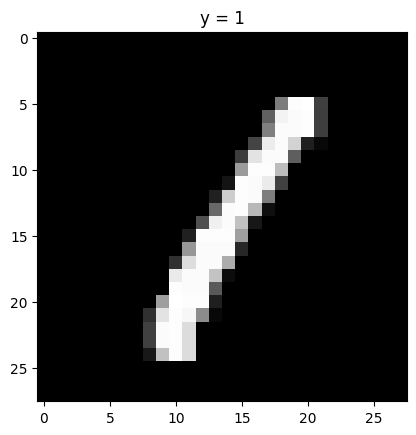

In [8]:
# Plot the fourth sample:
print("the image: ",show_data(train_dataset[3]))

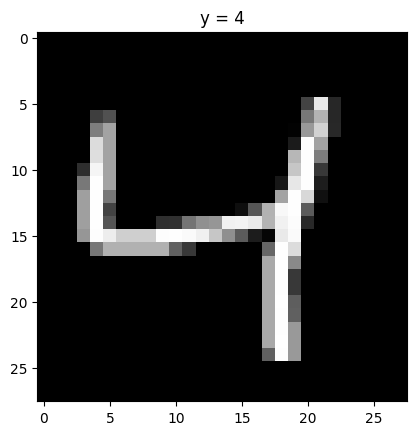

In [9]:
# plot the image
show_data(train_dataset[2])

## Build a Softmax Classifier

In [10]:
# Define softmax classifier class
class softmax(nn.Module):

    # Constructor
    def __init__(self, input_size, output_size):
        super(softmax,self).__init__()
        self.linear = nn.Linear(input_size,output_size)

    # Prediction
    def forward(self, x):
        z = self.linear(x)
        return z

In [11]:
# print the shape of train dataset

train_dataset[0][0].shape

torch.Size([1, 28, 28])

In [12]:
# set input size and output size

input_dim = 28 * 28
output_dim = 10

### Define Softmax , criterion , optimizer and train the model

In [13]:
# create the model
model = softmax(input_dim, output_dim)
print("print the model: \n",model)

print the model: 
 softmax(
  (linear): Linear(in_features=784, out_features=10, bias=True)
)


In [14]:
# print the parameters
print('w: ',list(model.parameters())[0].size())
print('b: ',list(model.parameters())[1].size())

w:  torch.Size([10, 784])
b:  torch.Size([10])


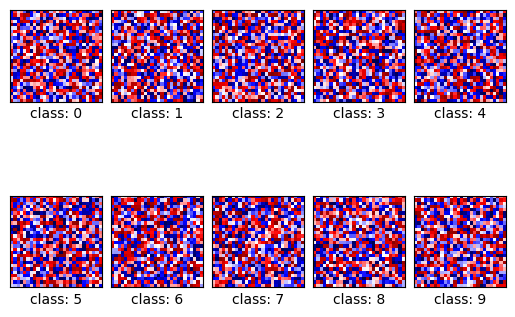

In [15]:
# plot the model parameters for each class
PlotParameters(model)

In [16]:
# define the lr , opt , criterion and dataloder

lr = 0.1
opt = torch.optim.SGD(model.parameters() ,lr = lr)
criterion = nn.CrossEntropyLoss()
train = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=100)
valid = torch.utils.data.DataLoader(dataset=validation_dataset, batch_size=5000)

In [17]:
# train the model 
n_epochs = 10
loss_list = []
accuracy_list = []
n_test = len(validation_dataset)

def train_model(n_epochs):
    for epoch in range(n_epochs):
        for x,y in train:
            opt.zero_grad()
            z = model(x.view(-1, 28 * 28))
            loss = criterion(z , y)
            loss.backward()
            opt.step()

        correct = 0
        # perform a prediction on the validation data
        for x_test, y_test in valid:
            z = model(x_test.view(-1, 28 * 28))
            _, yhat = torch.max(z.data, 1)
            correct += (yhat == y_test).sum().item()

        accuracy = correct / n_test
        loss_list.append(loss.data)
        accuracy_list.append(accuracy)


train_model(n_epochs)

## Analyze Results

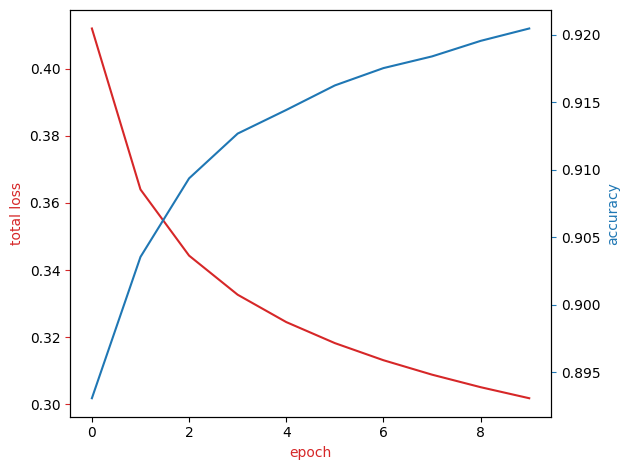

In [18]:
# Plot the loss and accuracy

fig, ax1 = plt.subplots()
color = 'tab:red'
ax1.plot(loss_list,color=color)
ax1.set_xlabel('epoch',color=color)
ax1.set_ylabel('total loss',color=color)
ax1.tick_params(axis='y', color=color)
    
ax2 = ax1.twinx()  
color = 'tab:blue'
ax2.set_ylabel('accuracy', color=color)  
ax2.plot( accuracy_list, color=color)
ax2.tick_params(axis='y', color=color)
fig.tight_layout()

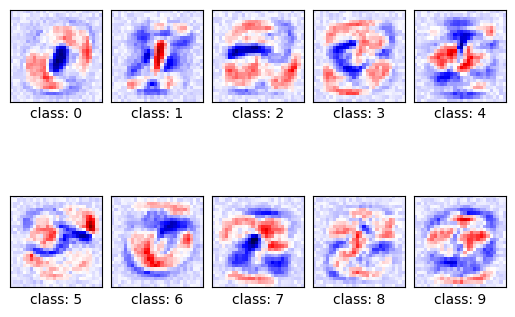

In [19]:
# plot the parameters
PlotParameters(model)

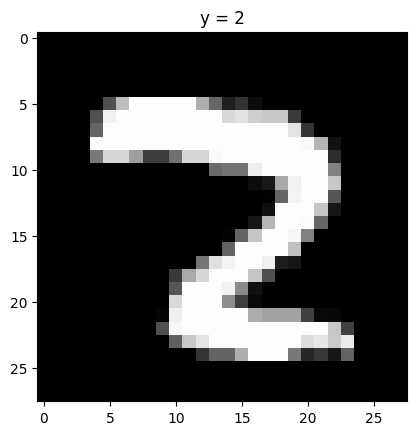

yhat: tensor([7])
probability of class  0.6758902072906494


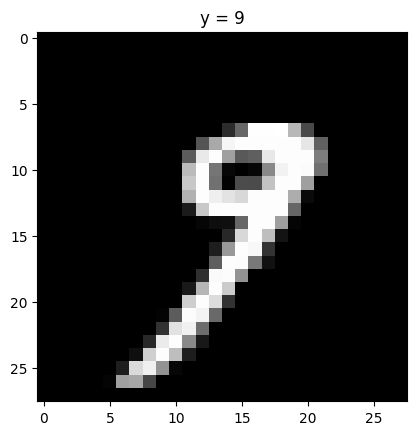

yhat: tensor([7])
probability of class  0.7115089297294617


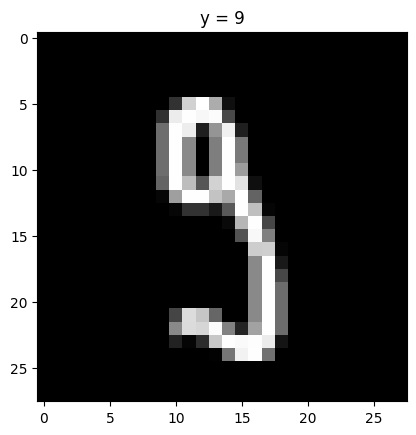

yhat: tensor([5])
probability of class  0.7233690619468689


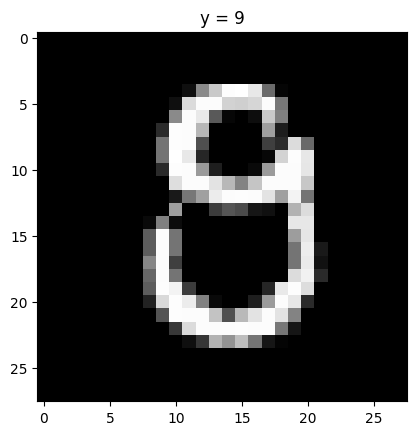

yhat: tensor([8])
probability of class  0.39026862382888794


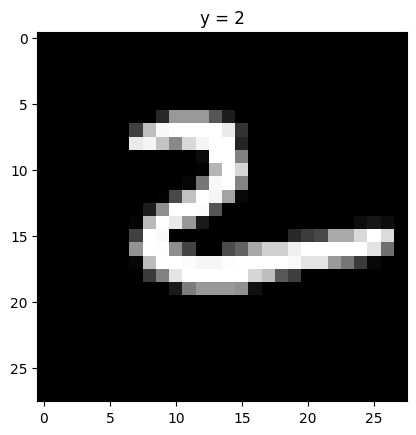

yhat: tensor([6])
probability of class  0.5119940638542175


In [20]:
# Plot the misclassified samples
Softmax_fn=nn.Softmax(dim=-1)
count = 0
for x, y in validation_dataset:
    z = model(x.reshape(-1, 28 * 28))
    _, yhat = torch.max(z, 1)
    if yhat != y:
        show_data((x, y))
        plt.show()
        print("yhat:", yhat)
        print("probability of class ", torch.max(Softmax_fn(z)).item())
        count += 1
    if count >= 5:
        break       

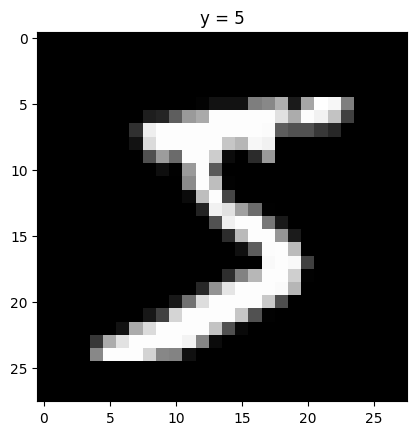

yhat: tensor([5])
probability of class  0.8423124551773071


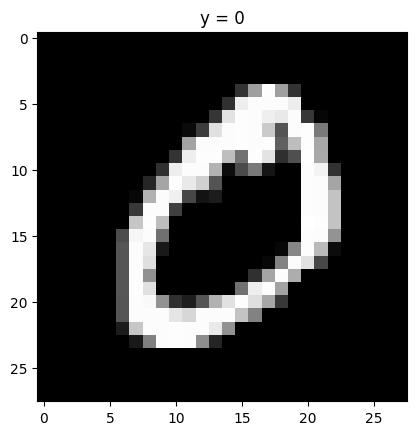

yhat: tensor([0])
probability of class  0.9996840953826904


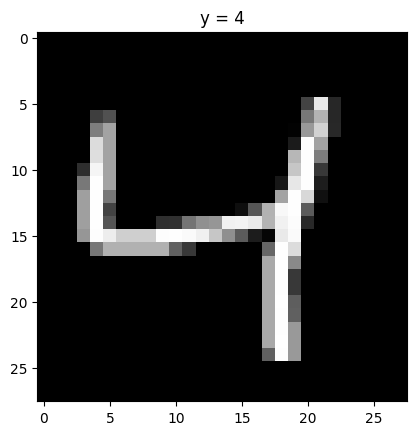

yhat: tensor([4])
probability of class  0.8743521571159363


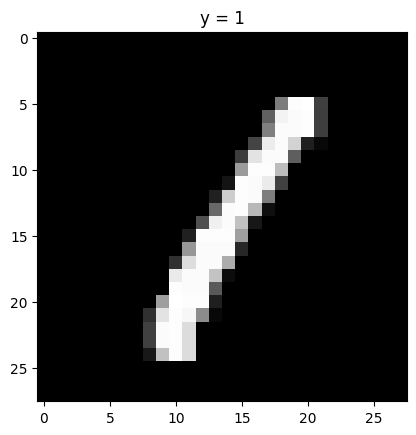

yhat: tensor([1])
probability of class  0.9658985733985901


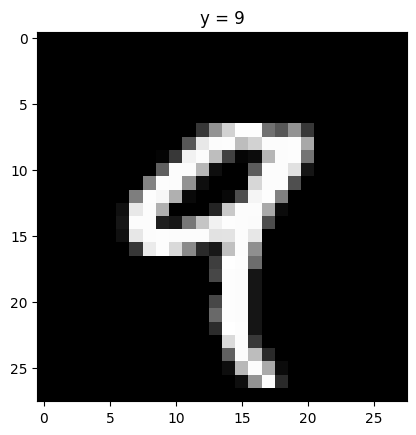

yhat: tensor([9])
probability of class  0.9233546853065491


In [21]:
# Plot the classified samples
Softmax_fn=nn.Softmax(dim=-1)
count = 0
for x, y in validation_dataset:
    z = model(x.reshape(-1, 28 * 28))
    _, yhat = torch.max(z, 1)
    if yhat == y:
        show_data((x, y))
        plt.show()
        print("yhat:", yhat)
        print("probability of class ", torch.max(Softmax_fn(z)).item())
        count += 1
    if count >= 5:
        break  